# Inspección de Data Products en Hogwarts
### Informe del Ministerio de Magia sobre evaluación trimestral

- **Asignatura:** Programación y entornos de trabajo para la IA
- **Estudiante:** Tania Évora Vargas Martínez
- **Módulo:** Python - Unidad Didáctica 1, 2 y 3
- **Universidad:** Alfonso X el Sabio
- **Fecha:** Noviembre 2025

Este informe analiza la evolución y calidad de los Data Products registrados en Hogwarts durante los tres trimestres del año 2024, con el fin de evaluar su estado y distribución por dominios y funcionarios.

## Procesamiento y preparación de Datos
En esta primera parte se realiza todo el trabajo necesario para dejar los datos preparados para el análisis. Aquí se documentan las transformaciones, comprobaciones y limpiezas realizadas sobre los datasets trimestrales proporcionados por el Ministerio de Magia. Las tareas incluyen:
- Verificación del esquema de columnas.
- Revisión del tipo de datos y su consistencia.
- Comprobación de formato en campos especiales como *ID*, *Name*, *Status*, *Version* y *NumberUsers*.
- Creación de columnas temporales (año y trimestre).
- Unión de los tres trimestres en un único DataFrame.

Esta preparación permite que el análisis sea fiable y consistente con las reglas establecidas por el Ministerio.

In [89]:
# Librerías para el procesamiento de datos
import pandas as pd
import numpy as np
import re

### 1. Carga de datos
Se importan los tres datasets correspondientes al años 2024, cada uno con la información trimestral sobre los Data Products en Hogwarts. 

Tras la carga inicial, se verifica que las columnas de los tres trimestres coincide con el esquema oficial definido en el enunciado (`ID`, `Name`, `Descriptive Name`, `Description`, `Domain`, `Owner`, `IsCompliance`, `Status`, `Version`, `NumberUsers`). 

Este paso garantiza que dataset son compatibles entre sí y pueden trabajarse en un único conjunto para su posterior análisis.


In [90]:
base = "Hogwards - 2024xT"

trim1_2024 = pd.read_csv(f"{base}\Hogwards - 20241T.csv")
trim2_2024 = pd.read_csv(f"{base}\Hogwards - 20242T.csv")
trim3_2024 = pd.read_csv(f"{base}\Hogwards - 20243T.csv")

In [91]:
# Comprobación de columnas esperadas
expected_cols = ["ID", "Name", "Descriptive Name", "Description", "Domain", "Owner", "IsCompliance", "Status", "Version", "NumberUsers"]

for df in [trim1_2024, trim2_2024, trim3_2024]:
  if df.columns.tolist() != expected_cols:
    print("Las columnas no coinciden con las esperadas.")
  else:
    print("Las columnas coinciden con las esperadas.")

Las columnas coinciden con las esperadas.
Las columnas coinciden con las esperadas.
Las columnas coinciden con las esperadas.


### 2. Revisión del esquema
A continuación se comprueba la estructura de cada dataset. Esto permite:
- Confirmar que las columnas tienen tipos de datos esperados.
- Verificar que no existen valores nulos.
- Comprobar la consistencia entre los tres datasets.

La columna *IsCompliance* aparece correctamente como booleana y *NumberUsers* como entero, mientras que el resto de campos que son de texto se representan como `object`, lo cual es apropiado.

In [92]:
trim1_2024.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   ID                50 non-null     object
 1   Name              50 non-null     object
 2   Descriptive Name  50 non-null     object
 3   Description       50 non-null     object
 4   Domain            50 non-null     object
 5   Owner             50 non-null     object
 6   IsCompliance      50 non-null     bool  
 7   Status            50 non-null     object
 8   Version           50 non-null     object
 9   NumberUsers       50 non-null     int64 
dtypes: bool(1), int64(1), object(8)
memory usage: 3.7+ KB


In [93]:
trim2_2024.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70 entries, 0 to 69
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   ID                70 non-null     object
 1   Name              70 non-null     object
 2   Descriptive Name  70 non-null     object
 3   Description       70 non-null     object
 4   Domain            70 non-null     object
 5   Owner             70 non-null     object
 6   IsCompliance      70 non-null     bool  
 7   Status            70 non-null     object
 8   Version           70 non-null     object
 9   NumberUsers       70 non-null     int64 
dtypes: bool(1), int64(1), object(8)
memory usage: 5.1+ KB


In [94]:
trim3_2024.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87 entries, 0 to 86
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   ID                87 non-null     object
 1   Name              87 non-null     object
 2   Descriptive Name  87 non-null     object
 3   Description       87 non-null     object
 4   Domain            87 non-null     object
 5   Owner             87 non-null     object
 6   IsCompliance      87 non-null     bool  
 7   Status            87 non-null     object
 8   Version           87 non-null     object
 9   NumberUsers       87 non-null     int64 
dtypes: bool(1), int64(1), object(8)
memory usage: 6.3+ KB


### 3. Validación de formatos y valores esperados
El enunciado define reglas concretas sobre el formato y valores permitidos en ciertas columnas (ID, Name, Status, Version y NumberUsers). Para asegurar que los datos cumplen estas reglas, se implementa una función de validación que revisa:
- **ID:** Es único, y sigue el patrón `DPXXX` con X entre 0 y 9.
- **Name:** No debe contener especios.
- **Status:** Debe ser uno de los cuatro estados oficiales.
- **Version:** Debe seguir el formato `X.X.X`
- **NumberUsers:** Debe estar entre 0 y 100.

Este proceso no corrige valores, únicamente detecta posibles inconsistencias, evitando modificaciones que puedan alterar el significado del dataset del Ministerio.

In [95]:
def format_check(df):
  # ID
  duplicated = df['ID'].duplicated().sum()
  if duplicated > 0:
    print(f"Hay {duplicated} IDs duplicados.")
  for id in df['ID']:
    if not re.match(r'^DP\d{3}$', id):
      print(f"ID inválido encontrado: {id}")
  # Name
  for name in df['Name']:
    if re.search(r"\s", name):
      print(f"Nombre inválido encontrado: {name}")
  # Status
  for status in df['Status']:
    if status not in ['Development', 'Planned', 'Production', 'Deprecated']:
      print(f"Status inválido encontrado: {status}")
  # Version
  for version in df['Version']:
    if not re.match(r'^\d\.\d\.\d$', str(version)):
      print(f"Version inválido encontrado: {version}")
  # NumberUsers
  for users in df['NumberUsers']:
    if not (0 <= users <= 100):
      print(f"NumberUsers inválido encontrado: {users}")
  print("Formato verificado")

format_check(trim1_2024)
format_check(trim2_2024)
format_check(trim3_2024)

Formato verificado
Formato verificado
Formato verificado


### 4. Creación de columnas temporales: Year y Trimester
Dado que los datos provienen de los tres trimestres del 2024 y la idea es unirlos, se añaden dos columnas nuevas a cada dataset:
- **Year:** Año del dataset (en este caso 2024).
- **Trimester:** Trimestre al que pertenece el registro (1, 2 o 3).

Estas columnas permiten, tras la unión de los tres datasets:
- Realizar análisis temporales.
- Generar visualizaciones de evolución trimestral.
- Ordenar y agrupar los Data Products en el tiempo.

In [96]:
trim1_2024["Year"] = 2024
trim2_2024["Year"] = 2024
trim3_2024["Year"] = 2024

trim1_2024["Trimester"] = 1
trim2_2024["Trimester"] = 2
trim3_2024["Trimester"] = 3

### 5. Unión de los datasets trimestrales
Una vez verificados los datos y añadida la información temporal, se combinan los tres datasets en un único. Este dataset contiene todos los Data Products recopilados a lo largo del año 2024, será la base para responder las preguntas de negocio planteadas por el Ministerio de Magia.

In [97]:
trimestres_2024 = pd.concat([trim1_2024, trim2_2024, trim3_2024], ignore_index=True)
trimestres_2024.head()

,ID,Name,Descriptive Name,Description,Domain,Owner,IsCompliance,Status,Version,NumberUsers,Year,Trimester
0,DP001,ProfeciaMonitor,Monitor de Pociones,"Data Product relacionado con adivinacion, util...",Adivinacion,Sybill Trelawney,True,Production,1.4.0,46,2024,1
1,DP002,CriaturaWatch,Sistema de Seguimiento de Hechizos,"Data Product relacionado con pociones, utiliza...",Pociones,Severus Snape,True,Production,2.6.9,100,2024,1
2,DP003,EstelarMap,Aplicacion de Transfiguraciones,"Data Product relacionado con pociones, utiliza...",Pociones,Severus Snape,False,Deprecated,0.4.1,38,2024,1
3,DP004,Transfigurator,Monitor de Pociones,"Data Product relacionado con transformaciones,...",Transformaciones,Minerva McGonagall,False,Development,2.9.6,99,2024,1
4,DP005,CriaturaWatch,Vigilante de Criaturas Magicas,"Data Product relacionado con transformaciones,...",Transformaciones,Minerva McGonagall,True,Production,2.3.7,51,2024,1


## Resultados y Visualización
En esta sección se presentan los resultados del análisis realizado sobre los datos trimestrales proporcionados por el Ministerio de Magia. Toda la información mostrada esta orientada a resolver las preguntas de negocio planteadas en el enunciado y a presentar los resultadosde manera clara, directa y visual.

In [98]:
# Librerías para la visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Extensión de SQL en Jupyter
%load_ext sql
%sql sqlite://
%sql drop table if exists trimestres_2024;
%sql --persist trimestres_2024
%config SqlMagic.style = '_DEPRECATED_DEFAULT'


The sql extension is already loaded. To reload it, use:
  %reload_ext sql
 * sqlite://
Done.
 * sqlite://


### 1. Estado actual de los Data Products: 
#### 1.1 Número total de Data Products 
Para conocer el estado de los Data Products, se contabiliza cúantos productos existen en cada dominio y como se distribuyen según su estado (*Development*, *Planned*, *Production*, *Deprecated*). Esta información permite identificar qué áreas están mejor preparadas y cuales podrían requerir atención.

In [128]:
query = """
  SELECT Domain, Status,
         COUNT(ID) AS DataProducts
  FROM trimestres_2024 
  GROUP BY Domain, Status;
"""
result_11 = %sql {query}
result_11_df = result_11.DataFrame()
result_11_df


 * sqlite://
Done.


,Domain,Status,DataProducts
0,Adivinacion,Deprecated,3
1,Adivinacion,Development,9
2,Adivinacion,Planned,3
3,Adivinacion,Production,17
4,Astronomia,Deprecated,1
5,Astronomia,Development,2
6,Astronomia,Planned,9
7,Astronomia,Production,5
8,Cuidado de Criaturas Magicas,Deprecated,3
9,Cuidado de Criaturas Magicas,Planned,5


A partir de los datos se observan varias diferencias entre los departamentos:

**Departamentos con mayor producción:**
- *Adivinación* destaca como el mejor departamento, con **17 productos en producción**, muy por encima del resto.
- *Pociones* también destaca, con **13 productos en producción**, aunque presenta un alto volumen de productos obsoletos (**7 en estado Deprecated**).

**Departamentos necesidades de mejora:**
- *Transformaciones* es el departamento con mayor número de productos obsoletos (**10 Deprecated**) y solo **5 en producción**, lo que refleja una alta necesidad de mejora.
- *Herbología* presenta un patrón similar, con **9 productos Deprecated** y únicamente *2 en producción**.
- *Encantamientos* acumula **8 productos Deprecated**; aunque cuenta con **6 en producción**, sería recomendable aumentar su ritmo de actualización para compensar o reducir los obsoletos.

**Departamentos estables:**

El resto de departamentos (*Astronomia*, *Cuidado de Criaturas Magicas*, *Defensa Contra las Artes Oscuras* e *Historia de la Magia*) presentan distribuciones más equilibradas. En algunos casos, el número de productos obsoletos supera a los que están en producción, pero esto se compensa con los productos en planificación o desarrollo. Aún así, se encuentran por debajo del nivel mostrado por los departamentos líderes.

### 2. Análisis trimestral de los Data Products en estado "Planned" o "Production": 
#### 2.1 Evolución de compliance
Para evaluar la cantidad de los Data Products activos que cumplen la normativa, se analiza cúantos productos en estado *Planned* y *Production* cumplen con las normas de compliance en cada trimestre.

In [130]:
query = """
  SELECT Trimester, 
         Status,
         COUNT(ID) AS DataProducts
  FROM trimestres_2024
  WHERE Status IN ('Planned', 'Production')
  AND IsCompliance = 1
  GROUP BY Trimester, Status;
"""
result_21 = %sql {query}
result_21_df = result_21.DataFrame()
result_21_df

 * sqlite://
Done.


,Trimester,Status,DataProducts
0,1,Planned,4
1,1,Production,10
2,2,Planned,7
3,2,Production,15
4,3,Planned,13
5,3,Production,15


Los resultado muestran un incremento progresivo en el número de Data Products que cumplen con las normas compliance a lo largo de los tres trimestres, lo que refleja una tendencia positiva en la gestión de normativas.
- En el estado *Planned*, el número aumenta de **4** en el primer trimestre a **7** en el segundo y alcanza los **13** en el tercero. Esto sugiere una mejora en la planificación, incorporando los requisitos normativos.
- En el estado *Production*, se observa un incremento inicial de **10** a **13** entre el primer y el segundo trimestre, manteniéndose estable en el tercero.

#### 2.2 Distribución del número de usuarios por departamento
A continuación se evalúa cuántos usuarios están utilizando los productos en estado *Planned* y *Production* en cada departamento. Esto permite encontrar qué áreas presentan mayor demanda y cuales requieren atención por el volumen reducido de usuarios.

In [101]:
query = """
  SELECT Trimester, 
         Status,
         Domain,
         SUM(NumberUsers) AS TotalUsers
  FROM trimestres_2024
  WHERE Status IN ('Planned', 'Production')
  GROUP BY Trimester, Status, Domain;
"""
result_22 = %sql {query}
result_22_df = result_22.DataFrame()
result_22_df

 * sqlite://
Done.


,Trimester,Status,Domain,TotalUsers
0,1,Planned,Astronomia,268
1,1,Planned,Cuidado de Criaturas Magicas,94
2,1,Planned,Defensa Contra las Artes Oscuras,81
3,1,Planned,Herbologia,372
4,1,Planned,Pociones,100
5,1,Planned,Transformaciones,27
6,1,Production,Adivinacion,259
7,1,Production,Astronomia,95
8,1,Production,Cuidado de Criaturas Magicas,89
9,1,Production,Defensa Contra las Artes Oscuras,96


El número de usuarios por departamento muestra distintos comportamientos según el estado del Data Product y el trimestre analizado.

**Departamentos en crecimiento:**

Algunos departamentos presentan un aumento constante de usuarios a lo largo del año. Este es el caso del estado *Planned* en *Herbologia* e *Historia de la Magia*, así como de *Adivinacion* en ambos estados. Cabe señalar que estos dos últimos departamento no cuentan con registros en el primer trimestre.

**Departamentos con incremento inicial y posterior estabilidad:**

Otros departamentos muestran un aumento entre el primer y segundo trimestre, pero posteriormente se mantienen sin cambios. Este patrón se observa principalmente en estado *Production* para *Astronomia*, *Pociones* y *Transformaciones*, mientras que en *Cuidado de Criaturas Magicas* ocurre tanto en *Planned* como en *Production*.

**Departamentos estables:**

En varios departamentos, el número de usuarios se mantiene constante durante los trimestres analizados. Esto sucede en el estado *Planned* en *Astronomia*, *Pociones* y *Transformaciones*, y en el estado Production en *Defensa Contra las Artes Oscuras*, *Herbologia*, *Encantamientos*, *Historia de la Magia*.

**Departamentos con volumen bajo de usuarios:**

Aunque la mayoría de departamentos cuentan con números elevados, algunos presentan valores notablemente bajos y que además no crecen con el tiempo: 
- *Transformaciones (Planned)*: 27 usuarios
- *Defensatra las Artes Oscuras (Production)*: 96 usuarios
- *Herbologia (Production)*: 33 usuarios
- *Historia de la Magia (Production)*: 56 usuarios

En general, la evolución es positiva, ya que en la mayoría de casos el número de usuarios se mantiene o aumenta respecto al trimestre anterior. Solo unos pocos departamento presentan cifras bajas o sin crecimiento, lo que podría señalar áreas donde sería necesario revisar o mejorar los Data Products.

#### 2.3 ¿Cuál es el promedio de usuarios por área? 

In [102]:
query = """
  SELECT Trimester, Status, Domain,
         ROUND(AVG(NumberUsers), 2) AS AvgUsers
  FROM trimestres_2024
  WHERE Status IN ('Planned', 'Production')
  GROUP BY Trimester, Status, Domain;
"""
result_23 = %sql {query}
result_23_df = result_23.DataFrame()
result_23_df

 * sqlite://
Done.


,Trimester,Status,Domain,AvgUsers
0,1,Planned,Astronomia,89.33
1,1,Planned,Cuidado de Criaturas Magicas,94.00
2,1,Planned,Defensa Contra las Artes Oscuras,81.00
3,1,Planned,Herbologia,93.00
4,1,Planned,Pociones,100.00
5,1,Planned,Transformaciones,27.00
6,1,Production,Adivinacion,64.75
7,1,Production,Astronomia,95.00
8,1,Production,Cuidado de Criaturas Magicas,44.50
9,1,Production,Defensa Contra las Artes Oscuras,96.00


#### 2.4  Y en aquellos que no cumplen con compliance, ¿cuántos usuarios tienen de todas formas? (¡Esto es importante para identificar posibles brechas de seguridad!). 

In [103]:
query = """
  SELECT Trimester, Status,
         SUM(NumberUsers) AS TotalUsers
  FROM trimestres_2024
  WHERE Status IN ('Planned', 'Production')
  AND IsCompliance = 0
  GROUP BY Trimester, Status;
"""
result_24 = %sql {query}
result_24_df = result_24.DataFrame()
result_24_df

 * sqlite://
Done.


,Trimester,Status,TotalUsers
0,1,Planned,561
1,1,Production,258
2,2,Planned,658
3,2,Production,414
4,3,Planned,812
5,3,Production,514


### 3. Análisis trimestral de los Data Products "Deprecated": 

In [104]:
query = """
  SELECT Trimester, Status,
         COUNT(ID) AS NumDataProducts
  FROM trimestres_2024
  WHERE Status = 'Deprecated'
  GROUP BY Trimester, Status;
"""
result_3 = %sql {query}
result_3_df = result_3.DataFrame()
result_3_df

 * sqlite://
Done.


,Trimester,Status,NumDataProducts
0,1,Deprecated,12
1,2,Deprecated,17
2,3,Deprecated,21


#### 3.1 ¿Cuántos Data Products en estado "Deprecated" hay en cada dominio? 

In [105]:
query = """
  SELECT Trimester, Domain,
         COUNT(ID) AS NumDataProducts
  FROM trimestres_2024
  WHERE Status = 'Deprecated'
  GROUP BY Trimester, Domain;
"""
result_31 = %sql {query}
result_31_df = result_31.DataFrame()
result_31_df

 * sqlite://
Done.


,Trimester,Domain,NumDataProducts
0,1,Adivinacion,1
1,1,Encantamientos,2
2,1,Herbologia,3
3,1,Historia de la Magia,2
4,1,Pociones,2
5,1,Transformaciones,2
6,2,Adivinacion,1
7,2,Cuidado de Criaturas Magicas,1
8,2,Defensa Contra las Artes Oscuras,1
9,2,Encantamientos,3


#### 3.2 ¿Cuántos usuarios siguen conectados a estos Data Products que, oficialmente, ya no están en servicio? 

In [106]:
query = """
  SELECT Trimester, 
         SUM(NumberUsers) AS TotalUsers
  FROM trimestres_2024
  WHERE Status = 'Deprecated'
  GROUP BY Trimester;
"""
result_32 = %sql {query}
result_32_df = result_32.DataFrame()
result_32_df

 * sqlite://
Done.


,Trimester,TotalUsers
0,1,668
1,2,959
2,3,1171


### 4. Análisis de los funcionarios (Owners) por cada trimestre: 

In [107]:
query = """
  SELECT Trimester, Owner, Status,
         COUNT(ID) AS TotalDataProducts
  FROM trimestres_2024
  GROUP BY Trimester, Owner, Status;
"""

result_4 = %sql {query}
result_4_df = result_4.DataFrame()
result_4_df

 * sqlite://
Done.


,Trimester,Owner,Status,TotalDataProducts
0,1,Alastor Moody,Production,1
1,1,Aurora Sinistra,Planned,3
2,1,Aurora Sinistra,Production,1
3,1,Cuthbert Binns,Deprecated,2
4,1,Cuthbert Binns,Development,3
...,...,...,...,...
102,3,Sybill Trelawney,Development,2
103,3,Sybill Trelawney,Planned,1
104,3,Sybill Trelawney,Production,3
105,3,Wilhelmina Grubbly-Plank,Deprecated,2


#### 4.1 ¿Cuántos funcionarios están trabajando, y cuántos Data Products (por estado) tienen asignados? 

In [108]:
query = """
  SELECT Trimester, 
         COUNT(DISTINCT Owner) AS NumOwners, 
         Status,
         COUNT(ID) AS NumDataProducts
  FROM trimestres_2024
  GROUP BY Trimester, Status;
"""

result_41 = %sql {query}
result_41_df = result_41.DataFrame()
result_41_df

 * sqlite://
Done.


,Trimester,NumOwners,Status,NumDataProducts
0,1,6,Deprecated,12
1,1,7,Development,12
2,1,6,Planned,11
3,1,11,Production,15
4,2,8,Deprecated,17
5,2,8,Development,14
6,2,8,Planned,16
7,2,12,Production,23
8,3,9,Deprecated,21
9,3,9,Development,18


#### 4.2 En cada dominio, ¿quiénes son los tres Owners con más usuarios en sus Data Products en estado "Planned" o "Production"? 

In [109]:
query = """
  SELECT Trimester, Domain, Owner, TotalUsers
  FROM (
    SELECT Trimester, Domain, Owner,
           SUM(NumberUsers) AS TotalUsers,
           ROW_NUMBER() OVER (PARTITION BY Trimester, Domain ORDER BY SUM(NumberUsers) DESC) AS row
    FROM trimestres_2024
    WHERE Status IN ('Planned', 'Production')
    GROUP BY Trimester, Domain, Owner
  ) 
  WHERE row <= 3
  ORDER BY Trimester, Domain, TotalUsers DESC;
"""

result_42 = %sql {query}
result_42_df = result_42.DataFrame()
result_42_df

 * sqlite://
Done.


,Trimester,Domain,Owner,TotalUsers
0,1,Adivinacion,Firenze,150
1,1,Adivinacion,Sybill Trelawney,109
2,1,Astronomia,Aurora Sinistra,363
3,1,Cuidado de Criaturas Magicas,Rubeus Hagrid,168
4,1,Cuidado de Criaturas Magicas,Wilhelmina Grubbly-Plank,15
5,1,Defensa Contra las Artes Oscuras,Alastor Moody,96
6,1,Defensa Contra las Artes Oscuras,Severus Snape,81
7,1,Encantamientos,Filius Flitwick,200
8,1,Herbologia,Pomona Sprout,372
9,1,Historia de la Magia,Cuthbert Binns,56


#### 4.3 Por otro lado, ¿quién es el Owner menos productivo en cada dominio? 
Esto significa que tiene el mayor porcentaje de Data Products en estado "Deprecated" sobre el total que le han asignado. Si hay empate, ¡queremos saber todos los nombres! 

In [110]:
query = """
  SELECT Trimester, Domain, Owner,
         Deprecated,
         TotalDataProducts,
         ROUND(DeprecatedRatio, 2) AS DeprecatedRatio
  FROM (
    SELECT Trimester, Domain, Owner,
           SUM(CASE WHEN Status = 'Deprecated' THEN 1 ELSE 0 END) AS Deprecated,
           COUNT(ID) AS TotalDataProducts,
           (SUM(CASE WHEN Status = 'Deprecated' THEN 1 ELSE 0 END) * 1.0) / COUNT(ID) AS DeprecatedRatio,
           RANK() OVER (PARTITION BY Trimester, Domain ORDER BY (SUM(CASE WHEN Status = 'Deprecated' THEN 1 ELSE 0 END) * 1.0) / COUNT(ID) DESC) AS row
    FROM trimestres_2024
    GROUP BY Trimester, Domain, Owner
  ) 
  WHERE row = 1
  ORDER BY Trimester, Domain;
"""

result_43 = %sql {query}
result_43_df = result_43.DataFrame()
result_43_df

 * sqlite://
Done.


,Trimester,Domain,Owner,Deprecated,TotalDataProducts,DeprecatedRatio
0,1,Adivinacion,Sybill Trelawney,1,5,0.20
1,1,Astronomia,Aurora Sinistra,0,4,0.00
2,1,Cuidado de Criaturas Magicas,Wilhelmina Grubbly-Plank,0,1,0.00
3,1,Cuidado de Criaturas Magicas,Rubeus Hagrid,0,2,0.00
4,1,Defensa Contra las Artes Oscuras,Severus Snape,0,2,0.00
5,1,Defensa Contra las Artes Oscuras,Alastor Moody,0,1,0.00
6,1,Encantamientos,Filius Flitwick,2,5,0.40
7,1,Herbologia,Pomona Sprout,3,7,0.43
8,1,Historia de la Magia,Cuthbert Binns,2,6,0.33
9,1,Pociones,Severus Snape,2,5,0.40


#### 4.4 Y finalmente, debido a la importancia de la ubicuidad, ¿hay algún funcionario que esté trabajando en varios dominios a la vez? El Ministerio quiere saber si tiene a algún mago "polifacético" en su equipo. 

In [111]:
query = """
  SELECT Trimester, Owner, NumDomains
  FROM (
    SELECT Trimester, Owner,
           COUNT(DISTINCT Domain) AS NumDomains
    FROM trimestres_2024
    GROUP BY Trimester,Owner
  )
  WHERE NumDomains > 1;
"""
result_44 = %sql {query}
result_44_df = result_44.DataFrame()
result_44_df

 * sqlite://
Done.


,Trimester,Owner,NumDomains
0,1,Severus Snape,2
1,2,Severus Snape,2
2,3,Severus Snape,2


## Conclusiones
*(Resumen de hallazgos clave y recomendaciones para el Ministerio de Magia.)*

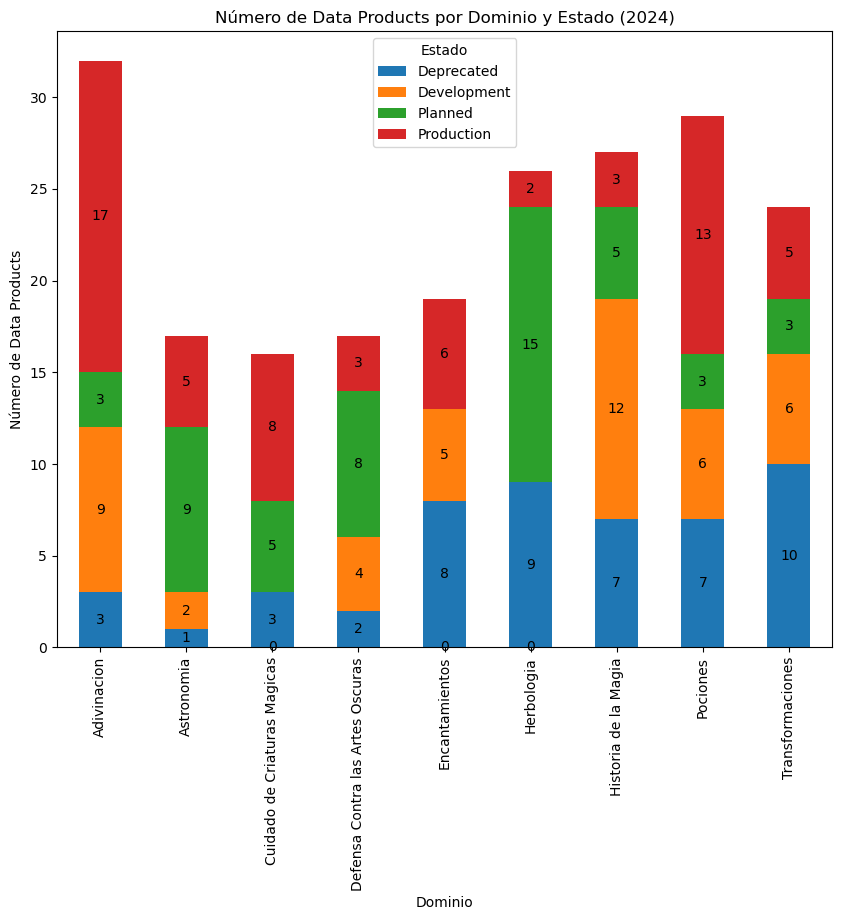

In [129]:
# Gráfica de Data Products actuales por dominio y su estado.
pivot_11 = result_11_df.pivot(index='Domain', columns='Status', values='DataProducts').fillna(0)
ax = pivot_11.plot(kind='bar', stacked=True, figsize=(10,8))
for container in ax.containers:
    ax.bar_label(container, label_type='center')
plt.title('Número de Data Products por Dominio y Estado (2024)')
plt.xlabel('Dominio')
plt.ylabel('Número de Data Products')
plt.legend(title='Estado')
plt.show()

 * sqlite://
Done.


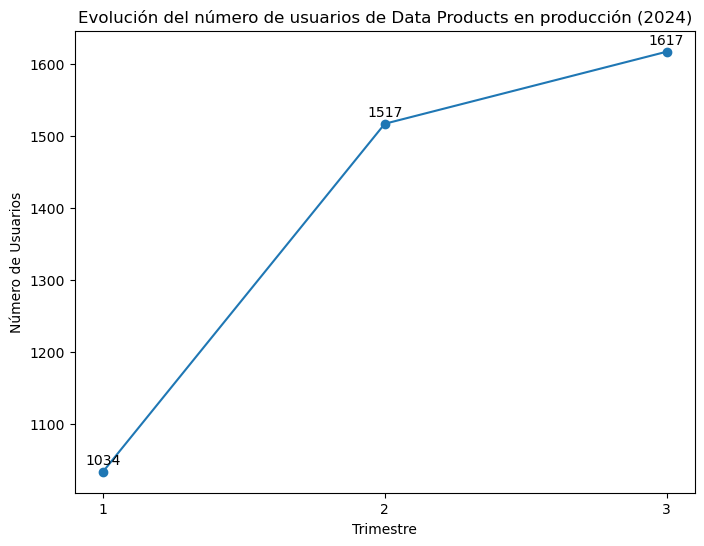

In [41]:
# Evolución temporal del número de usuarios de Data Products en producción.
query = """
  SELECT Trimester, 
         SUM(NumberUsers) AS TotalUsers
  FROM trimestres_2024
  WHERE Status = 'Production'
  GROUP BY Trimester; 
"""

graph_data2 = %sql {query}
graph_data2_df = graph_data2.DataFrame()

x = graph_data2_df['Trimester']
y = graph_data2_df['TotalUsers']

plt.figure(figsize=(8,6))
plt.plot( x, y, marker='o')
plt.title('Evolución del número de usuarios de Data Products en producción (2024)')
plt.xlabel('Trimestre')
plt.ylabel('Número de Usuarios')

plt.xticks(x)

for i, value in enumerate(y):
  plt.text(
    x.iloc[i], y.iloc[i] + 10,
    str(value),
    ha='center'
  )

plt.show()

 * sqlite://
Done.
 * sqlite://
Done.


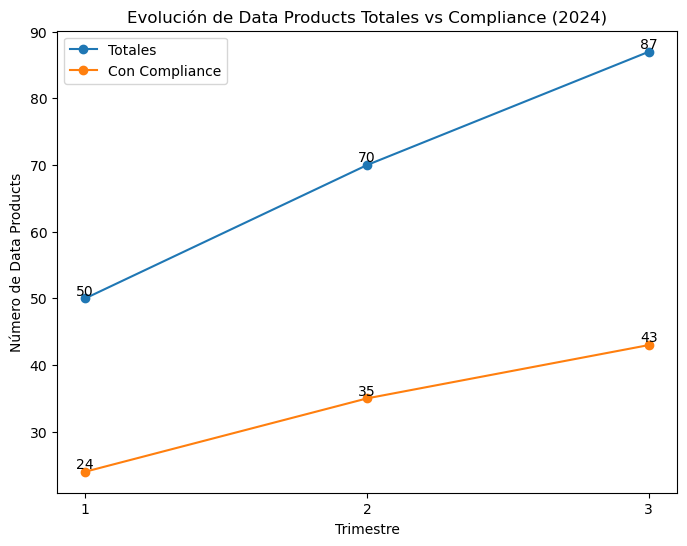

In [63]:
# Evolución temporal de Data Products totales frente a aquellos que cumplen con compliance.
# Total de Data Products por trimestre
query = """
  SELECT Trimester,
         COUNT(ID) AS NumDataProducts
  FROM trimestres_2024
  GROUP BY Trimester;
"""
total_dp = %sql {query}
total_dp_df = total_dp.DataFrame()

# Data Products que cumplen con compliance por trimestre
query_compliance = """
  SELECT Trimester, 
          COUNT(ID) AS NumDataProducts
  FROM trimestres_2024
  WHERE IsCompliance = 1
  GROUP BY Trimester;
"""
compliance_dp = %sql {query_compliance}
compliance_dp_df = compliance_dp.DataFrame()

merged_df = total_dp_df.merge(compliance_dp_df, on='Trimester', suffixes=('_Total', '_Compliance'))
merged_df

x = merged_df['Trimester']

plt.figure(figsize=(8,6))
plt.plot(x, merged_df['NumDataProducts_Total'], marker='o', label='Totales')
plt.plot(x, merged_df['NumDataProducts_Compliance'], marker='o', label='Con Compliance')

plt.title('Evolución de Data Products Totales vs Compliance (2024)')
plt.xlabel('Trimestre')
plt.ylabel('Número de Data Products')
plt.xticks(x)
plt.legend()

for i, value in enumerate(merged_df['NumDataProducts_Total']):
  plt.text(
    x.iloc[i], value + 0.5,
    str(value),
    ha='center'
  )
for i, value in enumerate(merged_df['NumDataProducts_Compliance']):
  plt.text(
    x.iloc[i], value + 0.5,
    str(value),
    ha='center'
  )
plt.show()


 * sqlite://
Done.


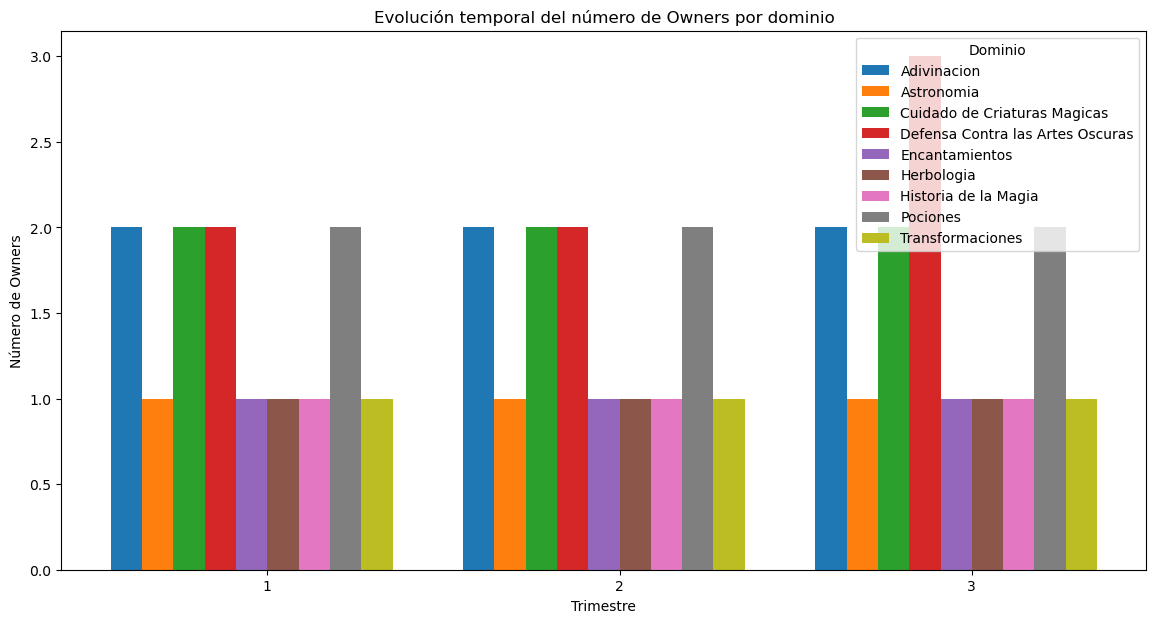

In [73]:
# Evolución temporal del número de Owners por dominio.
query = """
  SELECT Trimester, Domain,
         COUNT(DISTINCT Owner) AS NumOwners
  FROM trimestres_2024
  GROUP BY Trimester, Domain;
"""
owner_data = %sql {query}
owner_data_df = owner_data.DataFrame()

pivot = owner_data_df.pivot(index='Trimester', columns='Domain', values='NumOwners').fillna(0)
plt.figure(figsize=(14, 7))

x = pivot.index
dominios = pivot.columns
n = len(dominios)
bar_width = 0.8 / n
offset = [ (i - n / 2) * bar_width for i in range(n)]

for offset, dominio in zip(offset, dominios):
    plt.bar(x + offset, pivot[dominio], width=bar_width, label=dominio)
plt.title('Evolución temporal del número de Owners por dominio')
plt.xlabel('Trimestre')
plt.ylabel('Número de Owners')
plt.legend(title='Dominio')
plt.xticks(x)
plt.show()